# 03 · TGAT-BoostNet vs existing models
**Course 21CSC314P (SRMIST) · Distributed Streaming Anomaly Detection on Blockchain Transaction Graphs**

Two kinds of numbers appear here and are **never mixed**:

| Label | Meaning |
|---|---|
| **reproduced** | trained and scored by this notebook (or the cached runs it reads) on the identical split, seeds and threshold |
| **reported in paper** | transcribed from the paper's table, with citation; not re-run, not used for ranking |

Protocol for every reproduced model: train on labelled steps 1–34, test on labelled steps 35–49, illicit = positive,
threshold 0.5, hyper-parameters fixed a priori (published configuration where one exists, otherwise library
defaults). Stochastic models: 5 seeds (42, 123, 456, 789, 2024); deterministic ones (logistic regression): 1.

**Runtime:** ~10 min with the cached runs in `results/`; from scratch ~1.5 h on a Colab T4, ~8 h on a 10-core CPU.
The final cell writes an automatic, honest summary of where TGAT-BoostNet ranks.

## 0. Setup (Colab or local)
This cell clones the repository when run in Colab (fresh runtime), installs the dependencies, makes `src/`
importable, fixes seeds and detects a GPU. Locally it only locates the repository root.

**Data.** The Elliptic CSVs are looked up in `data/raw/elliptic`, `/content/elliptic` and Google Drive
(`MyDrive/elliptic`). If they are missing, the loader tries the Kaggle API (upload `kaggle.json` first:
`!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json`; dataset
`ellipticco/elliptic-data-set`), then falls back to a public mirror of the same three files.

In [1]:
import os, sys, subprocess, random, time, json, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Rayaanarora/blockchain-streaming-anomaly-detection.git"
REPO_BRANCH = "eval-notebooks"   # change to "main" once merged
MOUNT_DRIVE = False          # set True to read the CSVs from Google Drive (MyDrive/elliptic)
USE_CACHED_RESULTS = True    # True: reuse results/ shipped with the repo; False: retrain everything
QUICK = os.environ.get("BSAD_QUICK") == "1"   # smoke-test mode (tiny epochs, separate cache)

if IN_COLAB:
    ROOT = "/content/blockchain-streaming-anomaly-detection"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, ROOT], check=True)
    os.chdir(ROOT)
    import torch
    pkgs = ["torch_geometric", "xgboost>=2", "lightgbm", "catboost", "umap-learn", "seaborn", "plotly",
            "pyspark==3.5.0", "psutil", "kaggle"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)
    if MOUNT_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
else:
    ROOT = os.path.abspath(os.getcwd())
    while not os.path.exists(os.path.join(ROOT, "src", "evaluation")) and os.path.dirname(ROOT) != ROOT:
        ROOT = os.path.dirname(ROOT)
    os.chdir(ROOT)
sys.path.insert(0, ROOT)
if not USE_CACHED_RESULTS:   # recompute into a fresh cache (notebook 03 reuses what notebook 02 computed)
    os.environ["BSAD_RESULTS_DIR"] = os.path.join(ROOT, "results_fresh")
if QUICK:
    os.environ["BSAD_RESULTS_DIR"] = os.path.join(ROOT, "results_quick")
    os.environ["BSAD_FIG_DIR"] = os.path.join(ROOT, "results_quick", "figures")
    os.environ["BSAD_TAB_DIR"] = os.path.join(ROOT, "results_quick", "tables")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
from src.evaluation.tgat_boostnet import get_device
DEVICE = get_device()
print(f"repo={ROOT}  colab={IN_COLAB}  device={DEVICE}  torch={torch.__version__}  quick={QUICK}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
from src.evaluation import plotting as PL
PL.set_style()
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 4)

repo=D:\blockchainbigdata\blockchain-streaming-anomaly-detection  colab=False  device=cpu  torch=2.14.1+cpu  quick=False


## 1. Data

In [2]:
from src.evaluation.data import load_elliptic, SEEDS, standardise
from src.evaluation import baselines as B, stats as ST
from src.evaluation.metrics import full_metrics, METRIC_LABELS, METRIC_DIRECTION, per_timestep, fast_counts_metrics
from src.evaluation.literature import reported_table, SOURCES
data = load_elliptic()
tr, te = data.train_mask, data.test_mask
y_te, steps_te = data.y[te], data.time_steps[te]
OURS = B.OURS
LAB = {k: v[0] for k, v in B.MODELS.items()}
N_BOOT = 300 if QUICK else 2000
print(f"train {tr.sum()} labelled ({(data.y[tr] == 1).sum()} illicit) | test {te.sum()} ({(y_te == 1).sum()} illicit)")

Elliptic CSVs found in D:\blockchainbigdata\blockchain-streaming-anomaly-detection\data\raw\elliptic


train 29894 labelled (3462 illicit) | test 16670 (1083 illicit)


## 2. Published results — *reported in paper*
Transcribed from each paper's own table (same split: train 1–34 / test 35–49). See `src/evaluation/literature.py`
for the exact table numbers and caveats.

In [3]:
lit = reported_table()
lit_show = lit[["model", "features", "precision", "recall", "f1_illicit", "micro_f1", "auc", "seeds", "source", "year",
                "status"]].set_index(["source", "model", "features"])
PL.save_table(lit_show, "03_reported_in_paper", "Published Elliptic results (REPORTED IN PAPER; split 1-34 / 35-49)")
display(lit_show)
for k, v in SOURCES.items():
    print(f"[{k}] {v}")

precision  recall  f1_illicit  micro_f1    auc      seeds  year             status
source          model                         features                                                                                                      
Weber2019       Logistic Regression           AF (all 166)                    0.404   0.593       0.481     0.931    NaN          1  2019  reported in paper
                                              LF (local 94)                   0.348   0.668       0.457     0.920    NaN          1  2019  reported in paper
                                              AF + GCN emb.                   0.537   0.528       0.533     0.945    NaN          1  2019  reported in paper
                Random Forest                 AF (all 166)                    0.956   0.670       0.788     0.977    NaN          1  2019  reported in paper
                                              AF + GCN emb.                   0.971   0.675       0.796     0.978    NaN          1  2019  reported in paper
                                              LF (local 94)                   0.803   0.611       0.694     0.966    NaN          1  2019  reported in paper
                MLP                           AF (all 166)                    0.694   0.617       0.653     0.962    NaN          1  2019  reported in paper
                                              AF + GCN emb.                   0.780   0.617       0.689     0.967    NaN          1  2019  reported in paper
                GCN                           AF (all 166)                    0.812   0.512       0.628     0.961    NaN          1  2019  reported in paper
                Skip-GCN                      AF (all 166)                    0.812   0.623       0.705     0.966    NaN          1  2019  reported in paper
                EvolveGCN                     AF (all 166)                    0.850   0.624       0.720     0.968    NaN          1  2019  reported in paper
EllipticPP2023  Logistic Regression           Elliptic (EC)                   0.326   0.707       0.446     0.886    NaN        n/r  2023  reported in paper
                Random Forest                 Elliptic (EC)                   0.940   0.724       0.818     0.979    NaN        n/r  2023  reported in paper
                MLP                           Elliptic (EC)                   0.476   0.673       0.558     0.931    NaN        n/r  2023  reported in paper
                LSTM                          Elliptic (EC)                   0.665   0.350       0.459     0.946    NaN        n/r  2023  reported in paper
                XGBoost                       Elliptic (EC)                   0.812   0.717       0.761     0.971    NaN        n/r  2023  reported in paper
                RF + XGB ensemble             Elliptic (EC)                   0.960   0.704       0.812     0.979    NaN        n/r  2023  reported in paper
                RF + MLP + XGB ensemble       Elliptic (EC)                   0.947   0.719       0.817     0.979    NaN        n/r  2023  reported in paper
                Random Forest                 Elliptic++ (TX, +17 feats)      0.975   0.719       0.828     0.980    NaN        n/r  2023  reported in paper
InspectionL2022 Inspection-L (DGI emb. + RF)  AF + DGI emb.                   0.972   0.721       0.828       NaN  0.916        n/r  2022  reported in paper
                                              LF + DGI emb.                   0.906   0.712       0.797       NaN  0.895        n/r  2022  reported in paper
Maganti2026     3-layer MLP                   raw 165                         0.496   0.616       0.549       NaN  0.889  10 (mean)  2026  reported in paper
                GCN                           raw 165                         0.567   0.456       0.503       NaN  0.882  10 (mean)  2026  reported in paper
                GraphSAGE                     raw 165                         0.709   0.670       0.688       NaN  0.928  10 (mean)  2026  reported i

[Weber2019] M. Weber et al., 'Anti-Money Laundering in Bitcoin: Experimenting with Graph Convolutional Networks for Financial Forensics', KDD'19 Workshop on Anomaly Detection in Finance, 2019. arXiv:1908.02591. Tables 1 and 2.
[EllipticPP2023] Y. Elmougy and L. Liu, 'Demystifying Fraudulent Transactions and Illicit Nodes in the Bitcoin Network for Financial Forensics' (Elliptic++), KDD 2023. arXiv:2306.06108. Table 7.
[InspectionL2022] W. W. Lo et al., 'Inspection-L: Self-Supervised GNN Node Embeddings for Money Laundering Detection in Bitcoin', arXiv:2203.10465 (v4), 2022. Table 3.
[Maganti2026] S. Maganti, 'When Graph Structure Becomes a Liability: A Critical Re-Evaluation of Graph Neural Networks for Bitcoin Fraud Detection under Temporal Distribution Shift', arXiv:2604.19514, 2026. Tables 5 and 6.


## 3. Reproduced models on the identical split
`B.collect` loads each cached run or trains it. Models: logistic regression, SVM, random forest, XGBoost,
LightGBM, CatBoost, MLP, GCN, Skip-GCN, GraphSAGE, GAT alone, EvolveGCN-O, GAT+RF, GCN+XGBoost, GBDT-165 and
GBDT-197 without cost weighting.

In [4]:
keys = list(B.COMPARISON)
try:
    import catboost  # noqa: F401
except ImportError:
    keys.remove("catboost"); print("catboost not installed -> CatBoost skipped")
runs = B.collect(keys, data, DEVICE)
P = {k: [runs[k][s]["p_test"] for s in sorted(runs[k])] for k in keys}

def metric_frame(k):
    return pd.DataFrame([full_metrics(y_te, p) for p in P[k]])

MF = {k: metric_frame(k) for k in keys}
# The course's ten classification metrics first, then PR-AUC (the standard threshold-free score for rare classes).
SHOW = ["accuracy", "precision", "recall", "f1", "specificity", "roc_auc", "log_loss", "mcc", "kappa",
        "balanced_accuracy", "pr_auc"]
mean = pd.DataFrame({LAB[k]: MF[k][list(METRIC_LABELS)].mean() for k in keys}).T
std = pd.DataFrame({LAB[k]: MF[k][list(METRIC_LABELS)].std(ddof=1) for k in keys}).T.fillna(0)
mean = mean.sort_values("f1", ascending=False)
std = std.loc[mean.index]
board = pd.DataFrame({METRIC_LABELS[c]: [f"{m:.3f} ± {s:.3f}" for m, s in zip(mean[c], std[c])] for c in SHOW},
                     index=mean.index)
board.insert(0, "seeds", [len(P[k]) for k in [next(kk for kk in keys if LAB[kk] == lab) for lab in mean.index]])
board.insert(0, "status", "reproduced")
PL.save_table(board, "03_leaderboard", "Reproduced models, test steps 35-49, threshold 0.5 (mean ± std over seeds)",
              highlight_index=LAB[OURS])
PL.save_table(mean, "03_leaderboard_all_metrics_mean", "All metrics, mean over seeds", highlight_index=LAB[OURS])
PL.save_table(std, "03_leaderboard_all_metrics_std", "All metrics, std over seeds", highlight_index=LAB[OURS])
display(board)

,status,seeds,Accuracy,Precision (illicit),Recall (illicit),F1 (illicit),Specificity,ROC-AUC,Log-loss,MCC,Cohen's kappa,Balanced acc.,PR-AUC (AP)
CatBoost,reproduced,5,0.980 ± 0.000,0.953 ± 0.004,0.721 ± 0.003,0.821 ± 0.002,0.998 ± 0.000,0.938 ± 0.002,0.110 ± 0.001,0.819 ± 0.002,0.810 ± 0.002,0.859 ± 0.001,0.807 ± 0.001
GCN + XGBoost,reproduced,5,0.979 ± 0.001,0.949 ± 0.021,0.710 ± 0.007,0.812 ± 0.005,0.997 ± 0.001,0.920 ± 0.011,0.146 ± 0.011,0.811 ± 0.007,0.801 ± 0.006,0.854 ± 0.003,0.795 ± 0.007
GAT + RF,reproduced,5,0.978 ± 0.001,0.943 ± 0.024,0.708 ± 0.009,0.809 ± 0.005,0.997 ± 0.001,0.893 ± 0.008,0.171 ± 0.008,0.807 ± 0.007,0.797 ± 0.005,0.853 ± 0.004,0.772 ± 0.004
LightGBM,reproduced,5,0.977 ± 0.000,0.903 ± 0.000,0.729 ± 0.000,0.807 ± 0.000,0.995 ± 0.000,0.940 ± 0.000,0.119 ± 0.000,0.800 ± 0.000,0.795 ± 0.000,0.862 ± 0.000,0.803 ± 0.000
Random Forest,reproduced,5,0.977 ± 0.001,0.913 ± 0.011,0.722 ± 0.001,0.806 ± 0.004,0.995 ± 0.001,0.915 ± 0.010,0.127 ± 0.011,0.801 ± 0.005,0.794 ± 0.004,0.858 ± 0.001,0.783 ± 0.004
GBDT-197 (no cost weight),reproduced,5,0.977 ± 0.001,0.967 ± 0.017,0.675 ± 0.014,0.795 ± 0.007,0.998 ± 0.001,0.929 ± 0.004,0.127 ± 0.003,0.798 ± 0.006,0.783 ± 0.007,0.837 ± 0.007,0.792 ± 0.004
XGBoost,reproduced,5,0.976 ± 0.000,0.876 ± 0.000,0.728 ± 0.000,0.795 ± 0.000,0.993 ± 0.000,0.928 ± 0.000,0.140 ± 0.000,0.786 ± 0.000,0.782 ± 0.000,0.860 ± 0.000,0.799 ± 0.000
GBDT-165 (w=4.32),reproduced,5,0.975 ± 0.001,0.863 ± 0.010,0.733 ± 0.001,0.793 ± 0.004,0.992 ± 0.001,0.935 ± 0.004,0.114 ± 0.003,0.783 ± 0.005,0.780 ± 0.005,0.862 ± 0.001,0.802 ± 0.003
TGAT-BoostNet (ours),reproduced,5,0.976 ± 0.002,0.939 ± 0.038,0.683 ± 0.006,0.790 ± 0.011,0.997 ± 0.002,0.932 ± 0.005,0.122 ± 0.004,0.789 ± 0.015,0.778 ± 0.012,0.840 ± 0.002,0.792 ± 0.002
MLP,reproduced,5,0.953 ± 0.002,0.660 ± 0.026,0.585 ± 0.081,0.617 ± 0.040,0.979 ± 0.005,0.869 ± 0.008,0.381 ± 0.025,0.595 ± 0.036,0.592 ± 0.040,0.782 ± 0.038,0.497 ± 0.040


## 4. Reproduced vs reported, side by side
For every published model we also re-ran, both numbers are shown in separate, labelled columns.

In [5]:
rr = lit[lit.maps_to.notna() & lit.maps_to.isin(keys)].copy()
rr["reported F1 (paper)"] = rr.f1_illicit
rr["reproduced F1 (ours, mean ± std)"] = [f"{MF[k].f1.mean():.3f} ± {MF[k].f1.std(ddof=1) if len(MF[k]) > 1 else 0:.3f}"
                                         for k in rr.maps_to]
rr["reported AUC (paper)"] = rr.auc
rr["reproduced AUC"] = [round(MF[k].roc_auc.mean(), 3) for k in rr.maps_to]
rr["reproduction config"] = [LAB[k] for k in rr.maps_to]
rr = rr.set_index(["model", "source"])[["features", "reported F1 (paper)", "reproduced F1 (ours, mean ± std)",
                                        "reported AUC (paper)", "reproduced AUC", "reproduction config"]]
PL.save_table(rr, "03_reproduced_vs_reported", "Reproduced (this work) vs reported in paper")
display(rr)

,,features,reported F1 (paper),"reproduced F1 (ours, mean ± std)",reported AUC (paper),reproduced AUC,reproduction config
model,source,,,,,,
Logistic Regression,Weber2019,AF (all 166),0.481,0.405 ± 0.000,NaN,0.892,Logistic Regression
Random Forest,Weber2019,AF (all 166),0.788,0.806 ± 0.004,NaN,0.915,Random Forest
MLP,Weber2019,AF (all 166),0.653,0.617 ± 0.040,NaN,0.869,MLP
GCN,Weber2019,AF (all 166),0.628,0.545 ± 0.033,NaN,0.879,GCN
Skip-GCN,Weber2019,AF (all 166),0.705,0.584 ± 0.024,NaN,0.904,Skip-GCN
EvolveGCN,Weber2019,AF (all 166),0.720,0.424 ± 0.067,NaN,0.843,EvolveGCN-O
Logistic Regression,EllipticPP2023,Elliptic (EC),0.446,0.405 ± 0.000,NaN,0.892,Logistic Regression
Random Forest,EllipticPP2023,Elliptic (EC),0.818,0.806 ± 0.004,NaN,0.915,Random Forest
MLP,EllipticPP2023,Elliptic (EC),0.558,0.617 ± 0.040,NaN,0.869,MLP


## 5. Leaderboard heatmap, radar chart, ROC/PR overlay

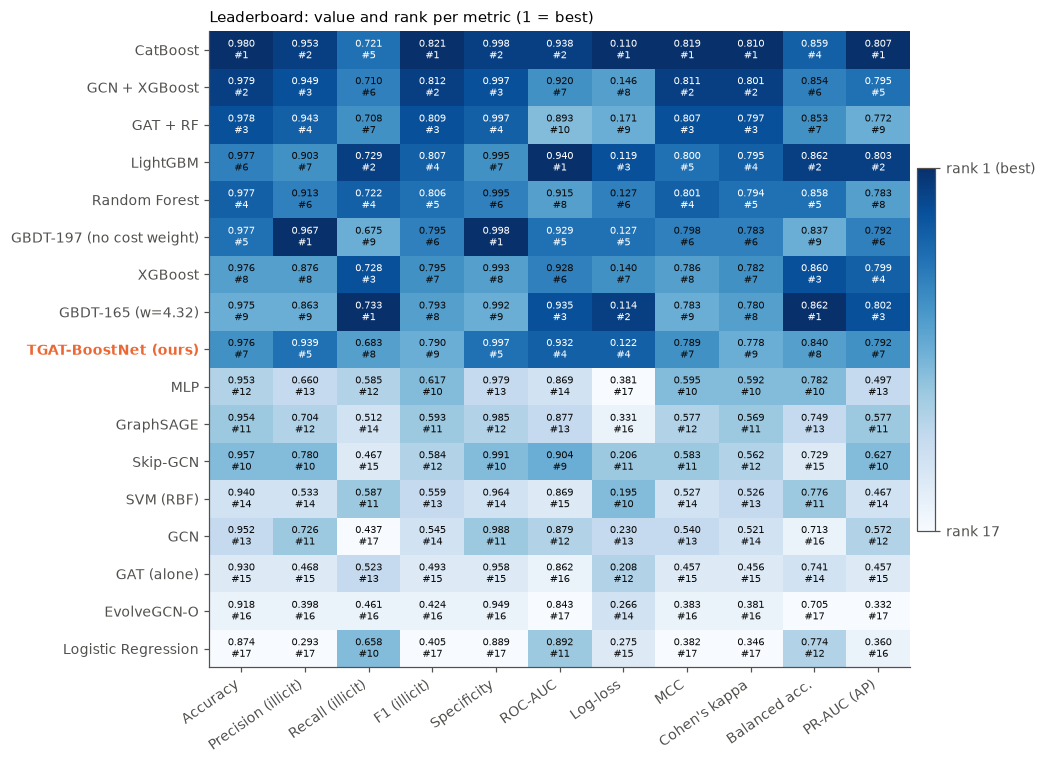

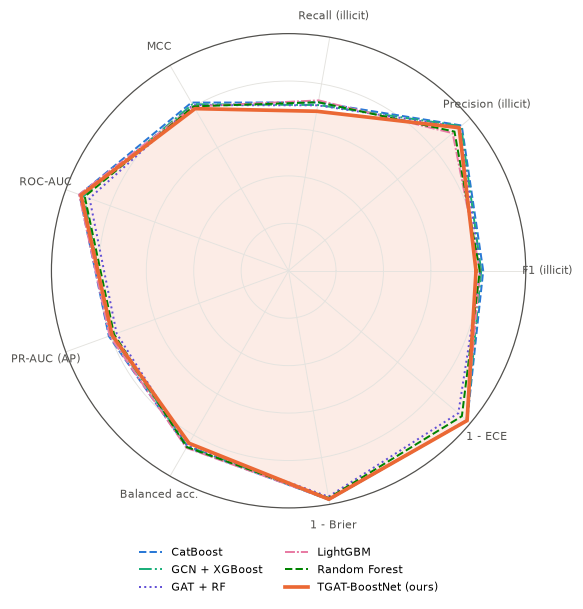

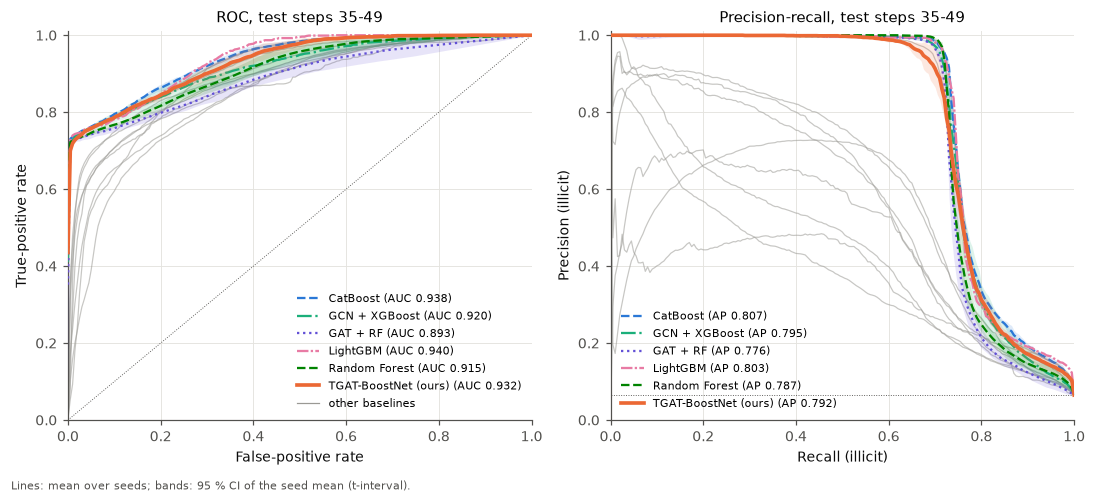

In [6]:
featured = [k for k in [next(kk for kk in keys if LAB[kk] == lab) for lab in mean.index] if k != OURS][:5]
ranks = ST.rank_table(mean[SHOW], METRIC_DIRECTION)
hm_vals = mean[SHOW].copy(); hm_vals.columns = [METRIC_LABELS[c] for c in SHOW]
hm_rank = ranks.copy(); hm_rank.columns = hm_vals.columns
fig = PL.heatmap_leaderboard(hm_vals, hm_rank, LAB[OURS], "Leaderboard: value and rank per metric (1 = best)")
PL.savefig(fig, "03_heatmap_leaderboard"); plt.show()
RAD = ["f1", "precision", "recall", "mcc", "roc_auc", "pr_auc", "balanced_accuracy"]
rad = mean[RAD].copy()
rad["1 - Brier"] = 1 - mean["brier"]; rad["1 - ECE"] = 1 - mean["ece"]
rad.columns = [METRIC_LABELS.get(c, c) for c in rad.columns]
rad.index = [next(kk for kk in keys if LAB[kk] == lab) for lab in rad.index]
fig = PL.radar(rad, OURS, featured, LAB); PL.savefig(fig, "03_radar"); plt.show()
fig = PL.roc_pr_overlay(y_te, P, LAB, OURS, featured); PL.savefig(fig, "03_roc_pr_overlay"); plt.show()

## 6. Seed variability (raincloud) and per-time-step F1

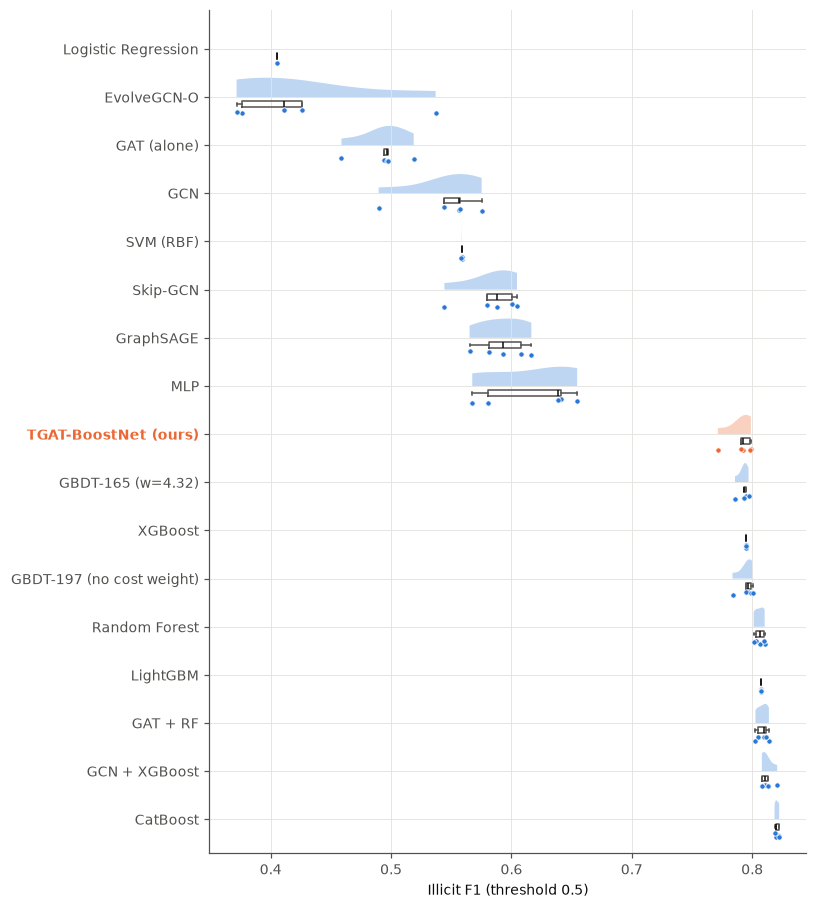

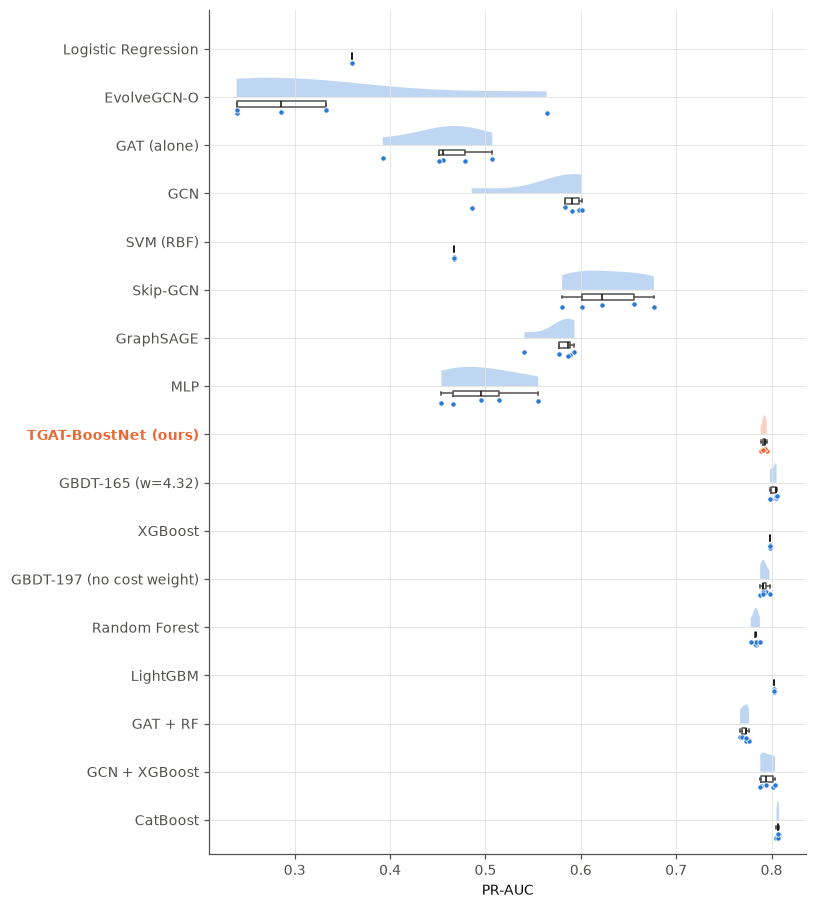

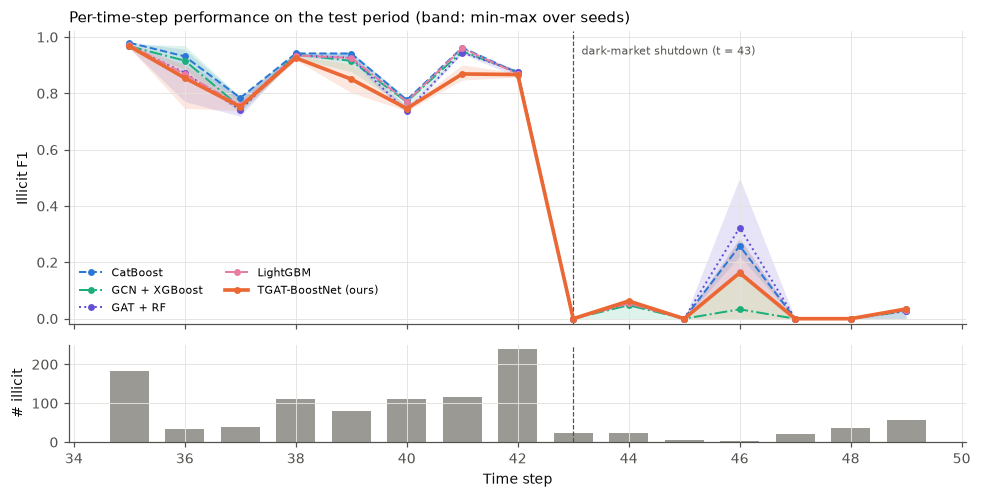

model,CatBoost,EvolveGCN-O,GAT (alone),GAT + RF,GBDT-165 (w=4.32),GBDT-197 (no cost weight),GCN,GCN + XGBoost,GraphSAGE,LightGBM,Logistic Regression,MLP,Random Forest,Skip-GCN,SVM (RBF),TGAT-BoostNet (ours),XGBoost
time_step,,,,,,,,,,,,,,,,,
35,0.980,0.727,0.769,0.968,0.969,0.969,0.838,0.968,0.857,0.973,0.789,0.879,0.967,0.888,0.828,0.968,0.964
36,0.932,0.175,0.275,0.873,0.851,0.879,0.261,0.916,0.469,0.868,0.206,0.597,0.865,0.407,0.416,0.855,0.831
37,0.784,0.347,0.379,0.741,0.796,0.753,0.521,0.751,0.648,0.758,0.458,0.552,0.764,0.550,0.396,0.753,0.824
38,0.942,0.516,0.470,0.936,0.935,0.922,0.683,0.938,0.765,0.935,0.564,0.783,0.942,0.719,0.551,0.926,0.926
39,0.942,0.478,0.501,0.926,0.932,0.852,0.540,0.916,0.436,0.926,0.378,0.657,0.926,0.535,0.548,0.851,0.932
40,0.777,0.426,0.486,0.736,0.766,0.740,0.422,0.770,0.611,0.771,0.498,0.654,0.774,0.458,0.535,0.746,0.751
41,0.963,0.466,0.475,0.945,0.960,0.874,0.512,0.949,0.583,0.961,0.435,0.621,0.944,0.520,0.642,0.869,0.940
42,0.873,0.645,0.700,0.877,0.852,0.872,0.674,0.875,0.725,0.869,0.679,0.712,0.868,0.708,0.778,0.867,0.860
43,0.000,0.012,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.034,0.005,0.000,0.000,0.000,0.000,0.000


In [7]:
long = pd.concat([MF[k].assign(label=LAB[k], seed=sorted(runs[k])) for k in keys])
order = list(mean.index)
for metric, lab in (("f1", "Illicit F1 (threshold 0.5)"), ("pr_auc", "PR-AUC")):
    fig = PL.raincloud(long, metric, order, LAB[OURS], lab); PL.savefig(fig, f"03_raincloud_{metric}"); plt.show()
rows = []
for k in keys:
    for s, p in zip(sorted(runs[k]), P[k]):
        rows += [dict(r, model=k, seed=s) for r in per_timestep(y_te, p, steps_te)]
pts = pd.DataFrame(rows)
counts = pts[(pts.model == OURS) & (pts.seed == SEEDS[0])].set_index("time_step").n_illicit
fig = PL.per_timestep_lines(pts, OURS, featured[:4], LAB, counts=counts); PL.savefig(fig, "03_per_timestep_f1"); plt.show()
pt_mean = pts.groupby(["model", "time_step"]).f1.mean().unstack(0).rename(columns=LAB)
PL.save_table(pt_mean, "03_per_timestep_f1", "Per-time-step illicit F1 (mean over seeds)")

## 7. Confusion matrices and calibration

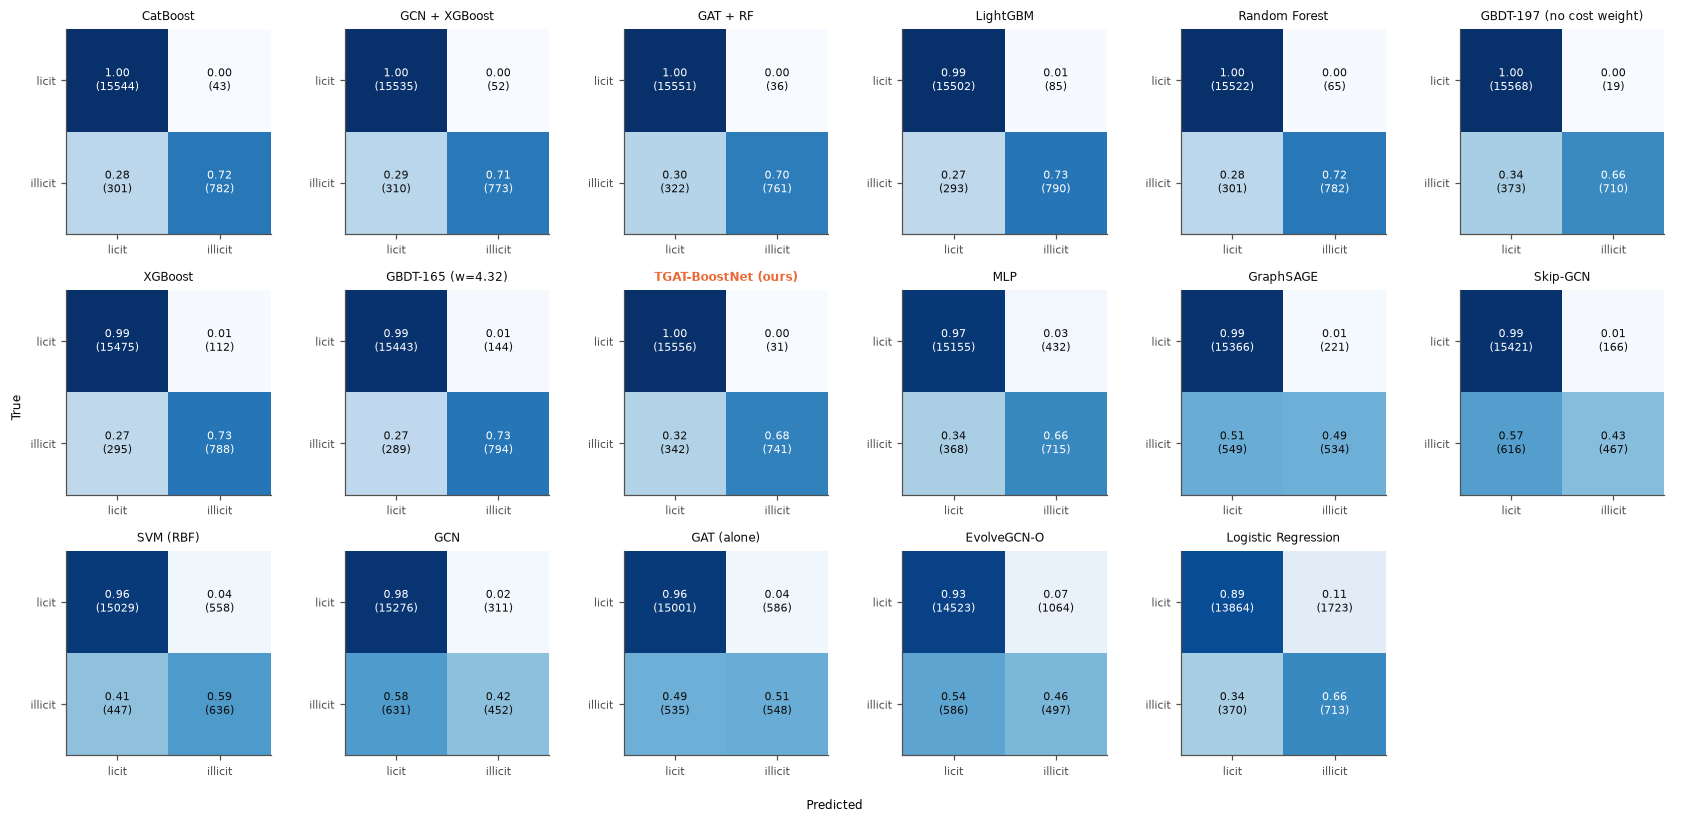

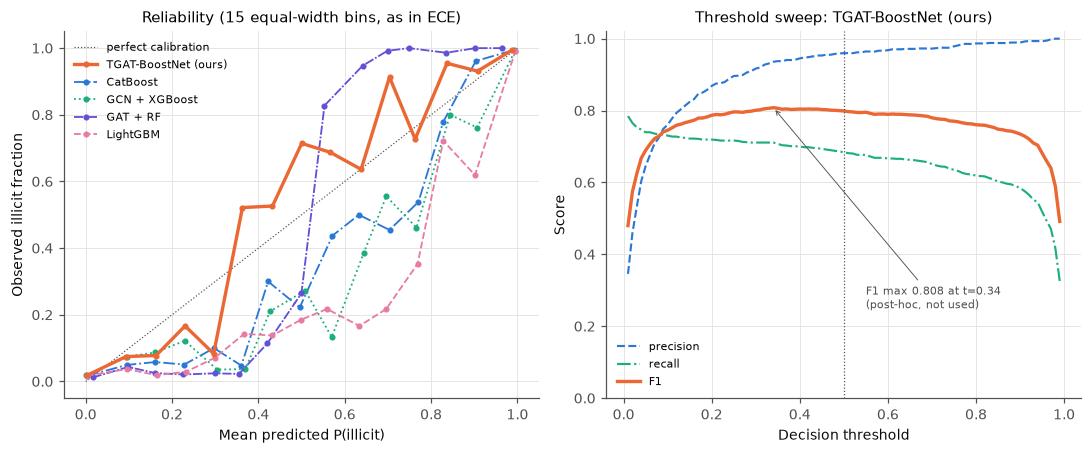

In [8]:
cms = {}
for k in [next(kk for kk in keys if LAB[kk] == lab) for lab in mean.index]:
    m = MF[k].iloc[0]
    cms[k] = np.array([[m.tn, m.fp], [m.fn, m.tp]])
fig = PL.confusion_grid(cms, LAB, OURS, ncols=6); PL.savefig(fig, "03_confusion_grid"); plt.show()
fig = PL.calibration_and_threshold(y_te, {k: P[k][0] for k in [OURS] + featured[:4]}, LAB, OURS, featured)
PL.savefig(fig, "03_calibration"); plt.show()

## 8. Statistical significance vs every baseline
* **McNemar (exact)** on the hard predictions of the seed-averaged probability (threshold 0.5).
* **Paired bootstrap** (2,000 resamples of test transactions) of the difference in 5-seed-mean F1 and PR-AUC.
* p-values Holm-corrected across the baselines. Positive Δ = TGAT-BoostNet better.

In [9]:
from sklearn.metrics import average_precision_score
f1_fn = lambda y, p: fast_counts_metrics(y, (p >= 0.5).astype(int))["f1"]
ap_fn = lambda y, p: average_precision_score(y, p)
pm = {k: np.mean(P[k], axis=0) for k in keys}
sig = {}
for k in keys:
    if k == OURS:
        continue
    mc = ST.mcnemar(y_te, (pm[OURS] >= 0.5).astype(int), (pm[k] >= 0.5).astype(int))
    bf = ST.paired_bootstrap(y_te, P[OURS], P[k], f1_fn, n_boot=N_BOOT)
    ba = ST.paired_bootstrap(y_te, P[OURS], P[k], ap_fn, n_boot=max(N_BOOT // 4, 100))
    sig[LAB[k]] = {"ΔF1": bf["diff"], "ΔF1 95% CI": f"[{bf['ci_low']:+.3f}, {bf['ci_high']:+.3f}]", "p (F1 boot)": bf["p_value"],
                   "ΔPR-AUC": ba["diff"], "ΔPR-AUC 95% CI": f"[{ba['ci_low']:+.3f}, {ba['ci_high']:+.3f}]",
                   "p (AP boot)": ba["p_value"], "McNemar b (ours right)": mc["a_right_b_wrong"],
                   "McNemar c (baseline right)": mc["a_wrong_b_right"], "p (McNemar)": mc["p_value"]}
sig = pd.DataFrame(sig).T
for col in ("p (F1 boot)", "p (AP boot)", "p (McNemar)"):
    sig[col + " Holm"] = sig.index.map(ST.holm(sig[col].astype(float).to_dict()))
sig = sig.sort_values("ΔF1")
def verdict(r):
    if float(r["p (F1 boot) Holm"]) < 0.05:
        return "ours significantly better (F1)" if r["ΔF1"] > 0 else "baseline significantly better (F1)"
    return "no significant F1 difference"
sig["verdict"] = sig.apply(verdict, axis=1)
for c in sig.columns:
    if c.startswith("Δ") and "CI" not in c or c.startswith("p ("):
        sig[c] = sig[c].astype(float)
PL.save_table(sig, "03_significance", "TGAT-BoostNet vs each baseline: paired bootstrap and McNemar (Holm-corrected)",
              float_fmt="{:.4f}")
display(sig[["ΔF1", "ΔF1 95% CI", "p (F1 boot) Holm", "ΔPR-AUC", "ΔPR-AUC 95% CI", "p (AP boot) Holm",
             "p (McNemar) Holm", "verdict"]])

,ΔF1,ΔF1 95% CI,p (F1 boot) Holm,ΔPR-AUC,ΔPR-AUC 95% CI,p (AP boot) Holm,p (McNemar) Holm,verdict
CatBoost,-0.0303,"[-0.039, -0.021]",0.000,-0.0144,"[-0.019, -0.010]",0.000,6.7546e-03,baseline significantly better (F1)
GCN + XGBoost,-0.0219,"[-0.030, -0.014]",0.000,-0.0032,"[-0.007, +0.001]",0.248,1.0386e-04,baseline significantly better (F1)
GAT + RF,-0.0184,"[-0.025, -0.011]",0.000,0.0204,"[+0.014, +0.027]",0.000,1.3556e-06,baseline significantly better (F1)
LightGBM,-0.0167,"[-0.027, -0.006]",0.005,-0.0108,"[-0.016, -0.006]",0.000,8.9578e-01,baseline significantly better (F1)
Random Forest,-0.0159,"[-0.026, -0.006]",0.024,0.0090,"[+0.003, +0.016]",0.000,8.9578e-01,baseline significantly better (F1)
GBDT-197 (no cost weight),-0.0047,"[-0.009, -0.001]",0.057,-0.0002,"[-0.002, +0.001]",0.840,8.9578e-01,no significant F1 difference
XGBoost,-0.0045,"[-0.016, +0.007]",0.946,-0.0065,"[-0.012, -0.002]",0.012,6.6762e-03,no significant F1 difference
GBDT-165 (w=4.32),-0.0025,"[-0.013, +0.008]",0.946,-0.0101,"[-0.014, -0.006]",0.000,2.0579e-03,no significant F1 difference
MLP,0.1737,"[+0.158, +0.190]",0.000,0.2860,"[+0.264, +0.305]",0.000,9.8827e-41,ours significantly better (F1)
GraphSAGE,0.1975,"[+0.178, +0.217]",0.000,0.2111,"[+0.187, +0.233]",0.000,1.1188e-73,ours significantly better (F1)


## 9. Critical-difference diagram and rank summary
Friedman test over the 15 test time steps (blocks; per-step F1, mean over seeds) and Nemenyi CD at α = 0.05.
Models joined by a bar are not significantly different. Steps after 43 have F1 ≈ 0 for most models (ties).

Friedman chi2 = 93.15, p = 6.54e-13, k = 17, N = 15, CD = 6.38


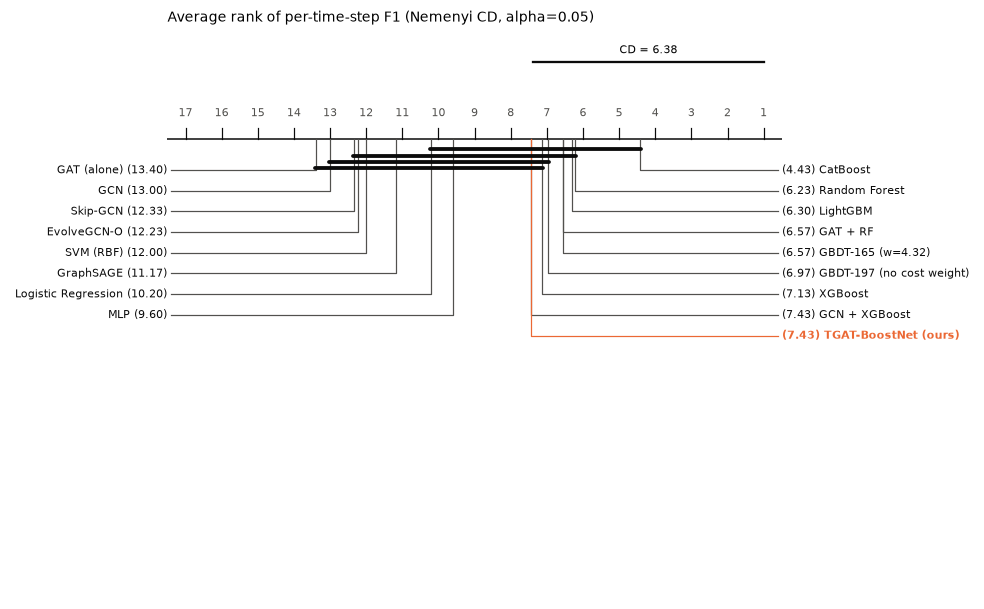

,Accuracy,Balanced acc.,Precision (illicit),Recall (illicit),F1 (illicit),F0.5 (illicit),F2 (illicit),Specificity,FPR,FNR,MCC,Cohen's kappa,F1 macro,F1 weighted,Precision macro,Recall macro,ROC-AUC,PR-AUC (AP),Log-loss,Brier,ECE (15 bins),mean rank,time-step avg rank (Friedman)
CatBoost,1,4,2,5,1,1,2,2,2,5,1,1,1,1,2,4,2,1,1,1,1,1.9524,4.4333
GCN + XGBoost,2,6,3,6,2,3,6,3,3,6,2,2,2,2,3,6,7,5,8,2,4,3.9524,7.4333
LightGBM,6,2,7,2,4,7,1,7,7,2,5,4,4,5,7,2,1,2,3,3,5,4.0952,6.3000
GBDT-197 (no cost weight),5,9,1,9,6,2,9,1,1,9,6,6,6,6,1,9,5,6,5,4,3,5.1905,6.9667
Random Forest,4,5,6,4,5,6,4,6,6,4,4,5,5,4,6,5,8,8,6,8,13,5.8095,6.2333
GBDT-165 (w=4.32),9,1,9,1,8,9,3,9,9,1,9,8,8,9,9,1,3,3,2,7,7,5.9524,6.5667
GAT + RF,3,7,4,7,3,4,7,4,4,7,3,3,3,3,4,7,10,9,9,9,16,6.0000,6.5667
XGBoost,8,3,8,3,7,8,5,8,8,3,8,7,7,8,8,3,6,4,7,6,6,6.2381,7.1333
TGAT-BoostNet (ours),7,8,5,8,9,5,8,5,5,8,7,9,9,7,5,8,4,7,4,5,2,6.4286,7.4333
Skip-GCN,10,15,10,15,12,10,15,10,10,15,11,12,12,11,10,15,9,10,11,10,8,11.4762,12.3333


In [10]:
blocks = pt_mean.copy()
fr = ST.friedman_nemenyi(blocks, higher_is_better=True)
print(f"Friedman chi2 = {fr['friedman_chi2']:.2f}, p = {fr['friedman_p']:.2e}, k = {fr['k']}, N = {fr['n_blocks']}, CD = {fr['cd']:.2f}")
fig = PL.cd_diagram(fr["avg_ranks"], fr["cd"], LAB[OURS], "Average rank of per-time-step F1 (Nemenyi CD, alpha=0.05)")
PL.savefig(fig, "03_critical_difference"); plt.show()
rank_all = ST.rank_table(mean[list(METRIC_LABELS)], METRIC_DIRECTION)
rank_all.columns = [METRIC_LABELS[c] for c in rank_all.columns]
rank_all["mean rank"] = rank_all.mean(1)
rank_all["time-step avg rank (Friedman)"] = fr["avg_ranks"].reindex(rank_all.index)
rank_all = rank_all.sort_values("mean rank")
PL.save_table(rank_all, "03_rank_summary", "Rank of each model on each metric (1 = best)", highlight_index=LAB[OURS],
              float_fmt="{:.2f}")
display(rank_all)

## 10. Ablation study
Each variant changes one component of TGAT-BoostNet and is run for the same 5 seeds:
no GAT (GBDT on 165 features), no cost weighting (w = 1), 1/2/4/8 attention heads, embedding dim 16/32/64,
+ temporal feature (time step given to the GAT as t/49 and to the GBDT), and raw (unstandardised) GAT input.

,F1,F1 sd,PR-AUC,PR-AUC sd,ROC-AUC,Precision,Recall,seeds,ΔF1 vs full,ΔPR-AUC vs full
"TGAT-BoostNet (4 heads, dim 32, w=4.32)",0.7903,0.0111,0.7922,0.0024,0.9315,0.9387,0.6829,5.0,0.0000,0.0000
no GAT (GBDT on 165),0.7927,0.0042,0.8022,0.0032,0.9353,0.8631,0.7330,5.0,0.0025,0.0101
no cost weighting (w = 1),0.7950,0.0066,0.7924,0.0037,0.9293,0.9674,0.6750,5.0,0.0047,0.0002
1 head,0.8076,0.0068,0.8006,0.0023,0.9365,0.9343,0.7114,5.0,0.0174,0.0084
2 heads,0.8063,0.0084,0.7990,0.0051,0.9331,0.9351,0.7088,5.0,0.0160,0.0069
8 heads,0.8035,0.0047,0.7985,0.0083,0.9350,0.9401,0.7019,5.0,0.0132,0.0063
embedding dim 16,0.8079,0.0056,0.8051,0.0021,0.9397,0.9402,0.7084,5.0,0.0177,0.0129
embedding dim 64,0.8000,0.0046,0.8017,0.0115,0.9354,0.9672,0.6822,5.0,0.0097,0.0095
+ temporal feature,0.8027,0.0039,0.7998,0.0044,0.9351,0.9470,0.6970,5.0,0.0124,0.0076
raw (unscaled) GAT input,0.8051,0.0059,0.7972,0.0039,0.9353,0.9502,0.6986,5.0,0.0149,0.0050


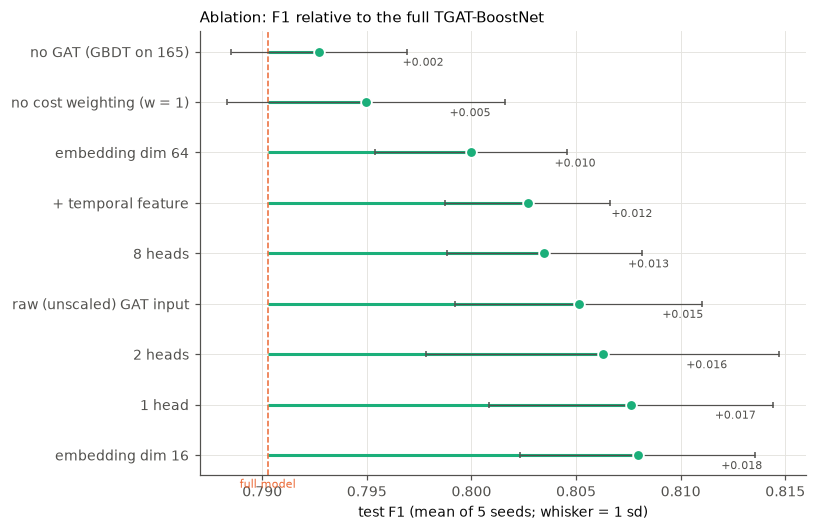

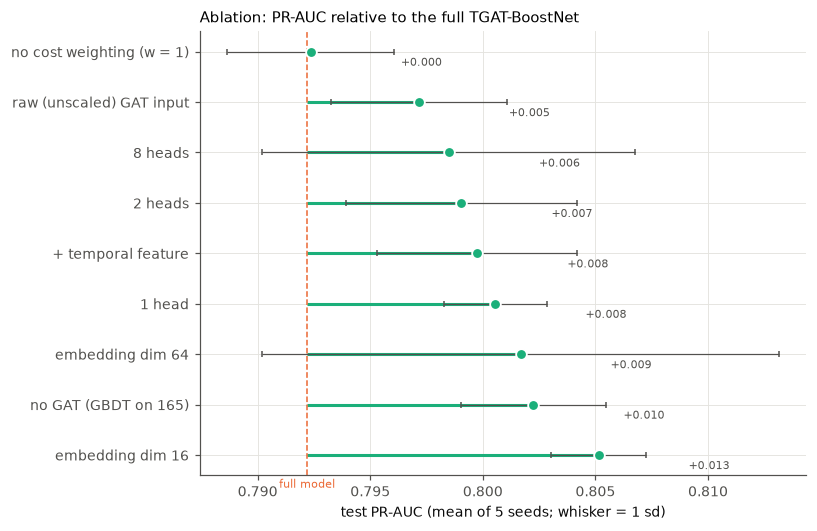

In [11]:
abl_keys = ["gbdt165_w", "gbdt197_unw"] + list(B.ABLATIONS)
abl_runs = B.collect(abl_keys, data, DEVICE)
ab = {}
for k in [OURS] + abl_keys:
    src = runs[k] if k in runs else abl_runs[k]
    mf = pd.DataFrame([full_metrics(y_te, src[s]["p_test"]) for s in sorted(src)])
    ab[k] = {"F1": mf.f1.mean(), "F1 sd": mf.f1.std(ddof=1), "PR-AUC": mf.pr_auc.mean(), "PR-AUC sd": mf.pr_auc.std(ddof=1),
             "ROC-AUC": mf.roc_auc.mean(), "Precision": mf.precision.mean(), "Recall": mf.recall.mean(), "seeds": len(mf)}
names = {OURS: "TGAT-BoostNet (4 heads, dim 32, w=4.32)", "gbdt165_w": "no GAT (GBDT on 165)",
         "gbdt197_unw": "no cost weighting (w = 1)", "abl_heads1": "1 head", "abl_heads2": "2 heads",
         "abl_heads8": "8 heads", "abl_dim16": "embedding dim 16", "abl_dim64": "embedding dim 64",
         "abl_temporal": "+ temporal feature", "abl_rawfeat": "raw (unscaled) GAT input"}
ab = pd.DataFrame(ab).T.rename(index=names)
ref = ab.loc[names[OURS]]
ab["ΔF1 vs full"] = ab.F1 - ref.F1
ab["ΔPR-AUC vs full"] = ab["PR-AUC"] - ref["PR-AUC"]
PL.save_table(ab, "03_ablation", "Ablation of TGAT-BoostNet (5 seeds each)", highlight_index=names[OURS])
display(ab)
for metric, err in (("F1", "F1 sd"), ("PR-AUC", "PR-AUC sd")):
    d = ab.drop(index=names[OURS]).sort_values(metric)
    fig = PL.lollipop(d, metric, err, ref[metric], "full model", f"test {metric} (mean of 5 seeds; whisker = 1 sd)",
                      f"Ablation: {metric} relative to the full TGAT-BoostNet")
    PL.savefig(fig, f"03_ablation_{metric.lower().replace('-', '')}"); plt.show()

## 10b. Validation-tuned models (from notebook 04)
Notebook 04 tunes TGAT-BoostNet **and** LightGBM, Random Forest and XGBoost with the same 40-trial budget on
steps 1–29 → 30–34 (test untouched), then refits on 1–34 and scores test once at the validation threshold.
This section reads those cached runs; run notebook 04 (GPU) first if they are missing.

In [12]:
import glob
sel_path = os.path.join(B.RESULTS_DIR, "tuning", "selected.json")
tuned_res, TUNED_SUMMARY = None, ""
if os.path.exists(sel_path) and glob.glob(os.path.join(B.RESULTS_DIR, "runs", "tgat_boostnet_tuned", "seed_*.json")):
    sel = json.load(open(sel_path))
    trows = {}
    for fam in sel:
        rr = [B.load_run(f"{fam}_tuned", s, data) for s in SEEDS]
        mf = pd.DataFrame([full_metrics(y_te, r["p_test"], sel[fam]["threshold"]) for r in rr])
        trows[f"{LAB[fam]} (tuned)"] = {"threshold": sel[fam]["threshold"], **{METRIC_LABELS[c]: mf[c].mean() for c in SHOW},
                                         "F1 sd": mf.f1.std(ddof=1)}
    for fam in sel:
        trows[f"{LAB[fam]} (untuned)"] = {"threshold": 0.5, **{METRIC_LABELS[c]: MF[fam][c].mean() for c in SHOW},
                                           "F1 sd": MF[fam].f1.std(ddof=1)}
    tuned_res = pd.DataFrame(trows).T.sort_values(METRIC_LABELS["f1"], ascending=False)
    PL.save_table(tuned_res, "03_tuned_vs_untuned", "Validation-tuned vs untuned (5 seeds each; tuned at validation threshold)",
                  highlight_index=[f"{LAB[OURS]} (tuned)", f"{LAB[OURS]} (untuned)"])
    display(tuned_res)
    r_t = list(tuned_res.index).index(f"{LAB[OURS]} (tuned)") + 1
    TUNED_SUMMARY = (f" With validation-only tuning applied equally to TGAT-BoostNet, LightGBM, Random Forest and XGBoost "
                     f"(notebook 04), TGAT-BoostNet reaches F1 {tuned_res.loc[f'{LAB[OURS]} (tuned)', METRIC_LABELS['f1']]:.3f} "
                     f"and ranks #{r_t} of {len(tuned_res)} tuned/untuned variants (best: {tuned_res.index[0]}, "
                     f"{tuned_res.iloc[0][METRIC_LABELS['f1']]:.3f}); significance in tables/04_significance_tuned.csv.")
else:
    print("no tuned runs cached - run notebooks/04_finetuning.ipynb first")

,threshold,Accuracy,Precision (illicit),Recall (illicit),F1 (illicit),Specificity,ROC-AUC,Log-loss,MCC,Cohen's kappa,Balanced acc.,PR-AUC (AP),F1 sd
LightGBM (tuned),0.90,0.9794,0.9459,0.7247,0.8206,0.9971,0.9366,0.2134,0.8180,0.8099,0.8609,0.8087,1.9457e-03
TGAT-BoostNet (ours) (tuned),0.37,0.9784,0.9459,0.7088,0.8103,0.9972,0.9373,0.1216,0.8085,0.7991,0.8530,0.8029,7.6253e-03
Random Forest (tuned),0.45,0.9778,0.9160,0.7241,0.8088,0.9954,0.9227,0.1234,0.8034,0.7972,0.8597,0.7921,6.2276e-03
LightGBM (untuned),0.50,0.9773,0.9029,0.7295,0.8069,0.9945,0.9400,0.1187,0.8001,0.7950,0.8620,0.8030,1.2413e-16
Random Forest (untuned),0.50,0.9774,0.9130,0.7217,0.8061,0.9952,0.9148,0.1274,0.8005,0.7943,0.8585,0.7832,4.0526e-03
XGBoost (untuned),0.50,0.9756,0.8756,0.7276,0.7948,0.9928,0.9277,0.1400,0.7857,0.7819,0.8602,0.7987,0.0000e+00
TGAT-BoostNet (ours) (untuned),0.50,0.9764,0.9387,0.6829,0.7903,0.9968,0.9315,0.1218,0.7894,0.7781,0.8399,0.7922,1.1132e-02
XGBoost (tuned),0.41,0.9732,0.8330,0.7352,0.7810,0.9897,0.9310,0.1334,0.7685,0.7668,0.8625,0.8008,5.6122e-03


## 11. Hyper-parameter sensitivity of the GBDT stage
One parameter at a time around the defaults, GAT embeddings fixed (cached, 5 seeds). **Post-hoc analysis — not
used to choose the reported configuration.** Two evaluation sets are shown: inner validation (fit on steps
1–29, score steps 30–34; uses only training data) and the test period.

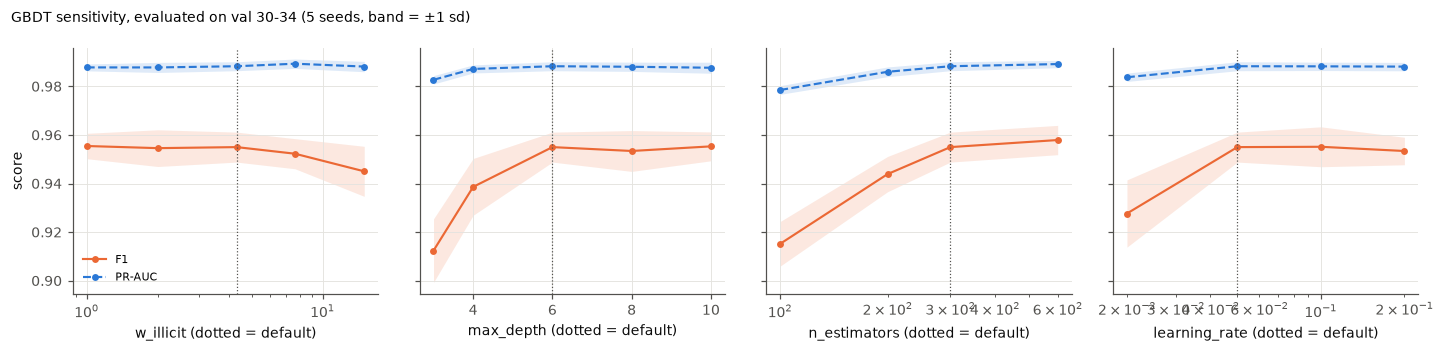

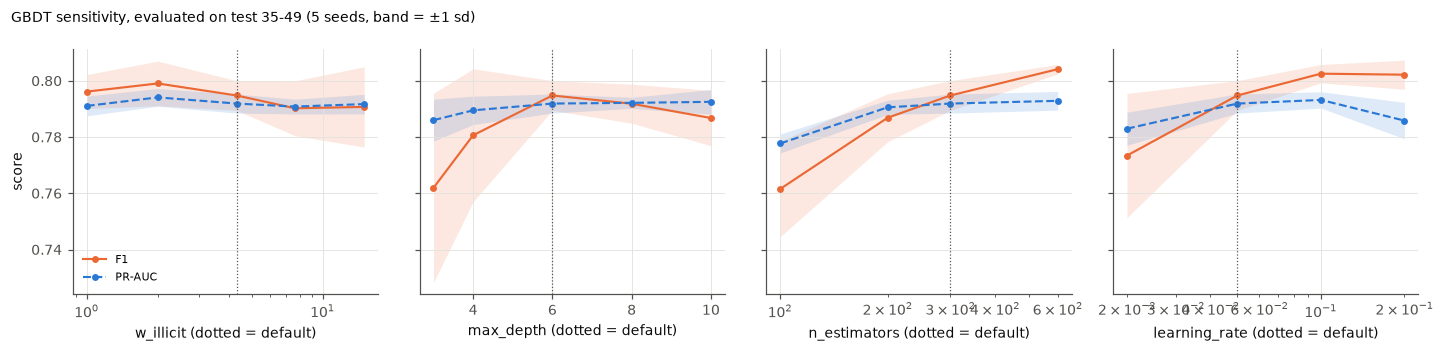

In [13]:
from src.evaluation.tgat_boostnet import DEFAULT_GBDT, make_xgb
Xs = standardise(data)[0]
GRID = {"w_illicit": [1, 2, 4.32, 7.63, 15], "max_depth": [3, 4, 6, 8, 10], "n_estimators": [100, 200, 300, 600],
        "learning_rate": [0.02, 0.05, 0.1, 0.2]}
DEF = dict(DEFAULT_GBDT, w_illicit=4.32)
sens_path = os.path.join(B.RESULTS_DIR, "sensitivity_gbdt.csv")
if os.path.exists(sens_path):
    sens = pd.read_csv(sens_path)
else:
    rows = []
    in_tr_steps = data.time_steps[tr]
    for s in SEEDS:
        e_tr, e_te = B.load_embeddings(OURS, s)
        F_tr, F_te = np.hstack([Xs[tr], e_tr]), np.hstack([Xs[te], e_te])
        fit_m, val_m = in_tr_steps <= 29, in_tr_steps >= 30
        for prm, vals in GRID.items():
            for v in vals:
                params = dict(DEF); params[prm] = v
                w = params.pop("w_illicit")
                for where, (Xa, ya, Xb, yb) in {"val 30-34": (F_tr[fit_m], data.y[tr][fit_m], F_tr[val_m], data.y[tr][val_m]),
                                                "test 35-49": (F_tr, data.y[tr], F_te, y_te)}.items():
                    clf = make_xgb(params, w, s, DEVICE); clf.fit(Xa, ya)
                    mm = full_metrics(yb, clf.predict_proba(Xb)[:, 1])
                    rows.append(dict(seed=s, param=prm, value=v, eval=where, f1=mm["f1"], pr_auc=mm["pr_auc"]))
    sens = pd.DataFrame(rows)
    if not QUICK:
        sens.to_csv(sens_path, index=False)
for where in ("val 30-34", "test 35-49"):
    fig = PL.sensitivity_grid(sens[sens["eval"] == where], list(GRID), DEF, {"f1": "F1", "pr_auc": "PR-AUC"})
    fig.suptitle(f"GBDT sensitivity, evaluated on {where} (5 seeds, band = ±1 sd)", x=0.01, ha="left", fontsize=9)
    fig.tight_layout(); PL.savefig(fig, f"03_sensitivity_{where.split()[0]}"); plt.show()
sens_tab = sens.groupby(["eval", "param", "value"])[["f1", "pr_auc"]].agg(["mean", "std"])
sens_tab.columns = [f"{a}_{b}" for a, b in sens_tab.columns]
PL.save_table(sens_tab, "03_sensitivity", "GBDT-stage sensitivity (post-hoc)", png=False)

## 12. Efficiency: latency / throughput vs F1 (Pareto)
Latency = median time to score one complete test time-step snapshot. Bubble area ∝ log model size.
Reference timings come from the idle-machine re-run of seed 42 (`results/timing/`) when available;
otherwise from the seed-42 training run (which shared the CPU with other workers).

,F1,PR-AUC,latency_ms,latency_p95_ms,throughput_tx_s,train_s,params,params_unit,size_kb,timing_source
CatBoost,0.8206,0.8066,5.5069,7.6942,8.1094e+05,15.5347,70000.0,tree leaves + splits,1110.7939,idle re-run
GCN + XGBoost,0.8121,0.7954,28.0228,39.4403,1.6247e+05,1904.5634,21464.0,GCN weights + tree nodes,288.0518,idle re-run
GAT + RF,0.8086,0.7717,41.1112,45.5285,1.1248e+05,495.6348,56002.0,GAT weights + tree nodes,2483.1348,idle re-run
LightGBM,0.8069,0.8030,6.8542,13.5114,6.1240e+05,0.8091,6100.0,tree nodes,355.9805,idle re-run
Random Forest,0.8061,0.7832,15.0970,16.2378,2.9538e+05,2.4603,28428.0,tree nodes,2237.4424,idle re-run
GBDT-197 (no cost weight),0.7950,0.7924,23.9630,31.6223,1.9208e+05,494.2001,42438.0,GAT weights + tree nodes,852.0439,idle re-run
XGBoost,0.7948,0.7987,4.7125,8.2195,8.6222e+05,0.8722,4620.0,tree nodes,218.5664,idle re-run
GBDT-165 (w=4.32),0.7927,0.8022,13.3121,61.7502,2.0282e+05,6.4634,19034.0,tree nodes,826.2139,idle re-run
TGAT-BoostNet (ours),0.7903,0.7922,22.6063,27.1336,2.1720e+05,495.2067,45054.0,GAT weights + GBDT tree nodes,938.9141,idle re-run
MLP,0.6166,0.4969,2.5221,3.5460,1.8260e+06,21.8667,8351.0,weights,141.3438,idle re-run


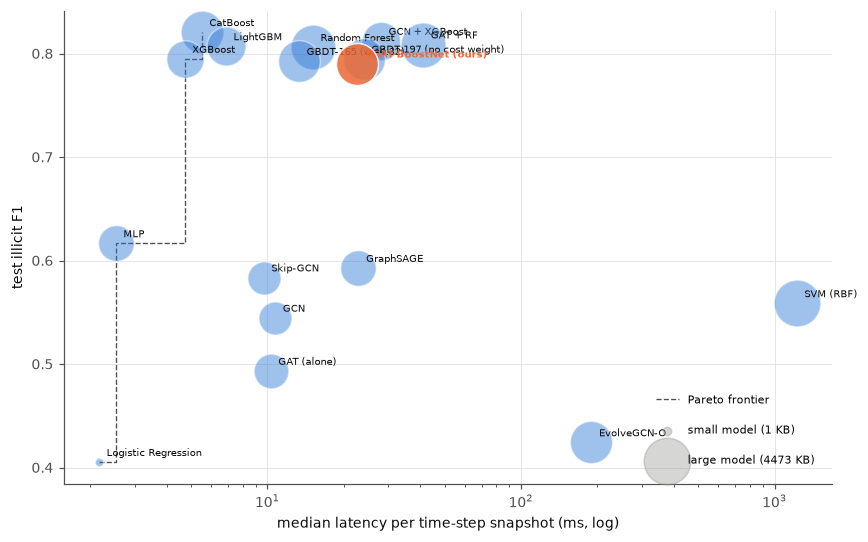

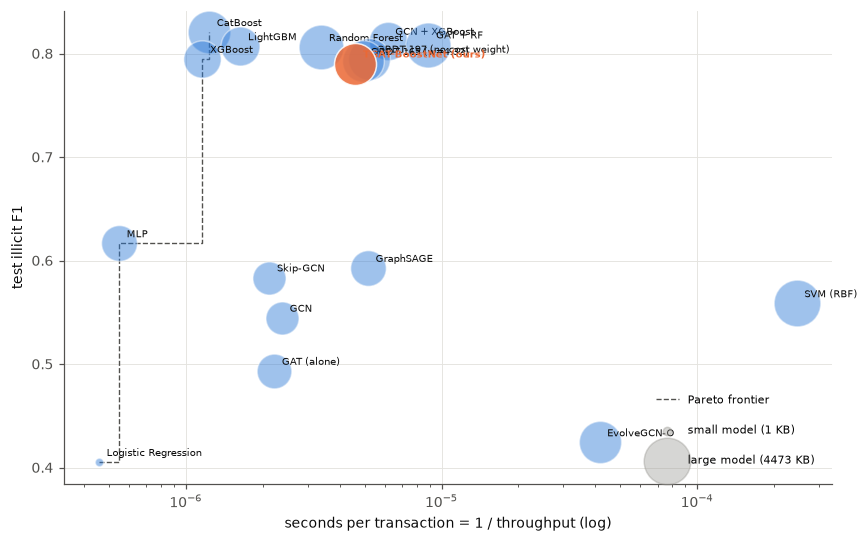

In [14]:
def timing(k):
    p = os.path.join(B.RESULTS_DIR, "timing", "runs", k, "seed_42.json")
    return (json.load(open(p)), "idle re-run") if os.path.exists(p) else (runs[k][SEEDS[0]], "training run")
eff = {}
for k in keys:
    t, srcname = timing(k)
    eff[LAB[k]] = {"F1": MF[k].f1.mean(), "PR-AUC": MF[k].pr_auc.mean(), "latency_ms": t["latency_ms_median"],
                   "latency_p95_ms": t["latency_ms_p95"], "throughput_tx_s": t["throughput_tx_per_s"],
                   "train_s": t["train_seconds"], "params": t["n_params"], "params_unit": t.get("n_params_note"),
                   "size_kb": t["size_bytes"] / 1024, "timing_source": srcname}
eff = pd.DataFrame(eff).T
for c in ("F1", "PR-AUC", "latency_ms", "latency_p95_ms", "throughput_tx_s", "train_s", "params", "size_kb"):
    eff[c] = eff[c].astype(float)
eff = eff.sort_values("F1", ascending=False)
PL.save_table(eff, "03_efficiency", "Efficiency (device: %s)" % runs[OURS][SEEDS[0]].get("device"),
              highlight_index=LAB[OURS], float_fmt="{:.3f}")
display(eff)
fig = PL.pareto(eff.assign(size_bytes=eff.size_kb * 1024), "latency_ms", "F1", "size_bytes", LAB[OURS],
                "median latency per time-step snapshot (ms, log)", "test illicit F1")
PL.savefig(fig, "03_pareto_latency_f1"); plt.show()
fig = PL.pareto(eff.assign(size_bytes=eff.size_kb * 1024, neg_tp=1.0 / eff.throughput_tx_s), "neg_tp", "F1", "size_bytes",
                LAB[OURS], "seconds per transaction = 1 / throughput (log)", "test illicit F1")
PL.savefig(fig, "03_pareto_throughput_f1"); plt.show()

## 13. Learning curves of the strongest models
Test F1 when trained on labelled steps 1..k only (5 seeds; ±1 sd). TGAT-BoostNet keeps its cached GAT
embeddings (GAT trained on 1–34) and refits only the GBDT, so its curve isolates the booster's data needs.

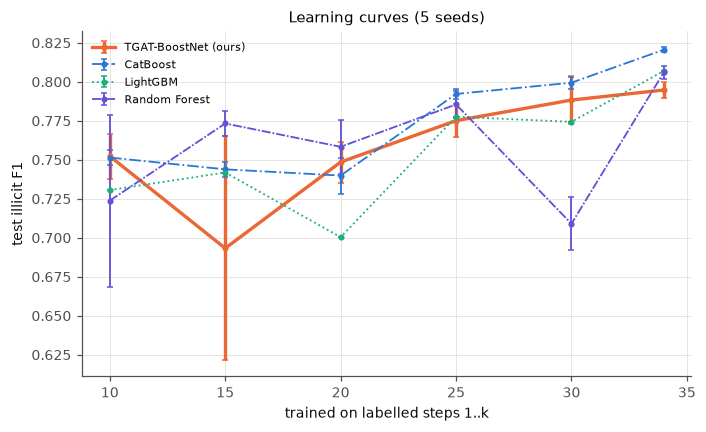

In [15]:
lc_path = os.path.join(B.RESULTS_DIR, "learning_curves.csv")
LC_MODELS = [OURS] + [k for k in featured if k in ("rf", "xgb", "lgbm", "gbdt165_w", "catboost")][:3]
if os.path.exists(lc_path):
    lcd = pd.read_csv(lc_path)
else:
    rows = []
    for kstep in (10, 15, 20, 25, 30, 34):
        m_tr = data.time_steps[tr] <= kstep
        for s in SEEDS:
            for k in LC_MODELS:
                if k == OURS:
                    e_tr, e_te = B.load_embeddings(OURS, s)
                    clf = make_xgb(DEFAULT_GBDT, 4.32, s, DEVICE)
                    clf.fit(np.hstack([Xs[tr], e_tr])[m_tr], data.y[tr][m_tr])
                    p = clf.predict_proba(np.hstack([Xs[te], e_te]))[:, 1]
                else:
                    clf = B._tabular(k, s, DEVICE); clf.fit(Xs[tr][m_tr], data.y[tr][m_tr])
                    p = clf.predict_proba(Xs[te])[:, 1]
                rows.append(dict(model=k, seed=s, last_step=kstep, f1=full_metrics(y_te, p)["f1"]))
    lcd = pd.DataFrame(rows)
    if not QUICK:
        lcd.to_csv(lc_path, index=False)
fig, ax = plt.subplots(figsize=(6.5, 4))
cmap = PL.colors_for(LC_MODELS, OURS, [k for k in LC_MODELS if k != OURS])
for i, k in enumerate(LC_MODELS):
    g = lcd[lcd.model == k].groupby("last_step").f1
    ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), color=cmap[k], lw=2.2 if k == OURS else 1.2, marker="o", ms=3,
                capsize=2, ls="-" if k == OURS else PL.LINESTYLES[1 + i % 4], label=LAB[k])
ax.set(xlabel="trained on labelled steps 1..k", ylabel="test illicit F1", title="Learning curves (5 seeds)")
ax.legend(); fig.tight_layout(); PL.savefig(fig, "03_learning_curves"); plt.show()

## 14. Results summary (generated from the numbers above)

In [16]:
def rank_of(metric):
    col = mean[metric]
    asc = METRIC_DIRECTION[metric] < 0
    order_ = col.sort_values(ascending=asc)
    return int(list(order_.index).index(LAB[OURS]) + 1), order_.index[0], order_.iloc[0]
n_models = len(mean)
lines = ["| Metric | TGAT-BoostNet (mean ± sd) | Rank (of %d reproduced) | Best reproduced model | Best value |" % n_models,
         "|---|---|---|---|---|"]
wins, losses = [], []
for c in SHOW:
    r, best, bv = rank_of(c)
    lines.append(f"| {METRIC_LABELS[c]} | {mean.loc[LAB[OURS], c]:.3f} ± {std.loc[LAB[OURS], c]:.3f} | {r} | {best} | {bv:.3f} |")
    (wins if r == 1 else losses).append((METRIC_LABELS[c], r, best))
table_md = "\n".join(lines)
sig_better = list(sig.index[(sig["p (F1 boot) Holm"] < 0.05) & (sig["ΔF1"] > 0)])
sig_worse = list(sig.index[(sig["p (F1 boot) Holm"] < 0.05) & (sig["ΔF1"] < 0)])
not_sig = list(sig.index[sig["p (F1 boot) Holm"] >= 0.05])
lit_best = lit.loc[lit.f1_illicit.idxmax()]
f1_ours = mean.loc[LAB[OURS], "f1"]
para = (f"Among {n_models} reproduced models on the identical split, TGAT-BoostNet ranks "
        f"**#{rank_of('f1')[0]} on illicit F1** ({f1_ours:.3f}), #{rank_of('pr_auc')[0]} on PR-AUC and "
        f"#{rank_of('roc_auc')[0]} on ROC-AUC. "
        + (f"It is first on: {', '.join(w[0] for w in wins)}. " if wins else "It is not first on any reported metric. ")
        + (f"Where it is not first: " + "; ".join(f"{m} (rank {r}, best = {b})" for m, r, b in losses) + ". " if losses else "")
        + f"Its F1 is significantly higher (paired bootstrap, Holm-corrected p < 0.05) than {len(sig_better)} baselines"
        + (f" ({', '.join(sig_better)})" if sig_better else "")
        + f", not significantly different from {len(not_sig)}"
        + (f" ({', '.join(not_sig)})" if not_sig else "")
        + f", and significantly lower than {len(sig_worse)}" + (f" ({', '.join(sig_worse)})" if sig_worse else "") + ". "
        + f"The highest published F1 on this split in our literature table is {lit_best.f1_illicit:.3f} "
        f"({lit_best.model}, {lit_best.features}, [{lit_best.source}], reported in paper, not reproduced here); "
        + ("TGAT-BoostNet's reproduced F1 is above it. " if f1_ours > lit_best.f1_illicit else
           "TGAT-BoostNet's reproduced F1 is below it. ")
        + "Like every model here, it fails after the step-43 dark-market shutdown (see §6)." + TUNED_SUMMARY)
display(Markdown("### Where TGAT-BoostNet ranks\n\n" + table_md + "\n\n" + para))
with open(os.path.join(PL.TAB_DIR, "03_results_summary.md"), "w", encoding="utf-8") as f:
    f.write("# Results summary (auto-generated by notebooks/03_model_comparison.ipynb)\n\n" + table_md + "\n\n" + para + "\n")

### Where TGAT-BoostNet ranks

| Metric | TGAT-BoostNet (mean ± sd) | Rank (of 17 reproduced) | Best reproduced model | Best value |
|---|---|---|---|---|
| Accuracy | 0.976 ± 0.002 | 7 | CatBoost | 0.980 |
| Precision (illicit) | 0.939 ± 0.038 | 5 | GBDT-197 (no cost weight) | 0.967 |
| Recall (illicit) | 0.683 ± 0.006 | 8 | GBDT-165 (w=4.32) | 0.733 |
| F1 (illicit) | 0.790 ± 0.011 | 9 | CatBoost | 0.821 |
| Specificity | 0.997 ± 0.002 | 5 | GBDT-197 (no cost weight) | 0.998 |
| ROC-AUC | 0.932 ± 0.005 | 4 | LightGBM | 0.940 |
| Log-loss | 0.122 ± 0.004 | 4 | CatBoost | 0.110 |
| MCC | 0.789 ± 0.015 | 7 | CatBoost | 0.819 |
| Cohen's kappa | 0.778 ± 0.012 | 9 | CatBoost | 0.810 |
| Balanced acc. | 0.840 ± 0.002 | 8 | GBDT-165 (w=4.32) | 0.862 |
| PR-AUC (AP) | 0.792 ± 0.002 | 7 | CatBoost | 0.807 |

Among 17 reproduced models on the identical split, TGAT-BoostNet ranks **#9 on illicit F1** (0.790), #7 on PR-AUC and #4 on ROC-AUC. It is not first on any reported metric. Where it is not first: Accuracy (rank 7, best = CatBoost); Precision (illicit) (rank 5, best = GBDT-197 (no cost weight)); Recall (illicit) (rank 8, best = GBDT-165 (w=4.32)); F1 (illicit) (rank 9, best = CatBoost); Specificity (rank 5, best = GBDT-197 (no cost weight)); ROC-AUC (rank 4, best = LightGBM); Log-loss (rank 4, best = CatBoost); MCC (rank 7, best = CatBoost); Cohen's kappa (rank 9, best = CatBoost); Balanced acc. (rank 8, best = GBDT-165 (w=4.32)); PR-AUC (AP) (rank 7, best = CatBoost). Its F1 is significantly higher (paired bootstrap, Holm-corrected p < 0.05) than 8 baselines (MLP, GraphSAGE, Skip-GCN, SVM (RBF), GCN, GAT (alone), EvolveGCN-O, Logistic Regression), not significantly different from 3 (GBDT-197 (no cost weight), XGBoost, GBDT-165 (w=4.32)), and significantly lower than 5 (CatBoost, GCN + XGBoost, GAT + RF, LightGBM, Random Forest). The highest published F1 on this split in our literature table is 0.828 (Random Forest, Elliptic++ (TX, +17 feats), [EllipticPP2023], reported in paper, not reproduced here); TGAT-BoostNet's reproduced F1 is below it. Like every model here, it fails after the step-43 dark-market shutdown (see §6). With validation-only tuning applied equally to TGAT-BoostNet, LightGBM, Random Forest and XGBoost (notebook 04), TGAT-BoostNet reaches F1 0.810 and ranks #2 of 8 tuned/untuned variants (best: LightGBM (tuned), 0.821); significance in tables/04_significance_tuned.csv.

## 15. Download figures and tables

In [17]:
import zipfile
zp = os.path.join(ROOT, "03_model_comparison_outputs.zip")
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as zf:
    for d in (PL.FIG_DIR, PL.TAB_DIR):
        for f in sorted(os.listdir(d)):
            if f.startswith("03_"):
                zf.write(os.path.join(d, f), os.path.join(os.path.basename(d), f))
print("wrote", zp)
if IN_COLAB:
    from google.colab import files
    files.download(zp)

wrote D:\blockchainbigdata\blockchain-streaming-anomaly-detection\03_model_comparison_outputs.zip
